# Fitur statistik out-of-fold: mencegah kebocoran target

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab04_hybrid_cf/02_fitur_statistik_out_of_fold.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 4 · Kode 4.4.1

**Tujuan belajar**

- Memahami mengapa rata-rata rating per pengguna atau item harus dihitung out-of-fold untuk data latih.
- Mengukur kerusakan akibat kebocoran pada pengguna dengan sedikit rating.
- Melihat peran penghalusan (m) pada rata-rata yang bertumpu pada sedikit data.

> **Catatan.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

> Model hilir di notebook ini adalah `HistGradientBoostingRegressor` dari scikit-learn (bukan LightGBM seperti pada eksperimen di buku), agar tidak memerlukan pustaka tambahan.

## 1. Kode dari buku

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingRegressor


def oof_mean(train, key, k=5, m=5, seed=0):
    """Rata-rata rating per `key` (user atau item) dengan penghalusan m, out-of-fold."""
    gmean = train['rating'].mean()
    out = np.empty(len(train))
    for fit_idx, enc_idx in KFold(n_splits=k, shuffle=True, random_state=seed).split(train):
        stats = train.iloc[fit_idx].groupby(key)['rating'].agg(['sum', 'count'])
        keys = train.iloc[enc_idx][key]
        s = keys.map(stats['sum']).fillna(0).to_numpy()
        c = keys.map(stats['count']).fillna(0).to_numpy()
        out[enc_idx] = (s + m * gmean) / (c + m)
    return out


def oof_mean_test(train, test, key, m=5):
    """Untuk data uji: statistik dari seluruh data latih, tanpa skema lipatan."""
    gmean = train['rating'].mean()
    stats = train.groupby(key)['rating'].agg(['sum', 'count'])
    s = test[key].map(stats['sum']).fillna(0).to_numpy()
    c = test[key].map(stats['count']).fillna(0).to_numpy()
    return (s + m * gmean) / (c + m)

## 2. Data simulasi dengan pengguna berjejak tipis

Jumlah rating per pengguna sangat timpang (lognormal): sepertiga lebih pengguna hanya punya satu rating. Itulah situasi saat kebocoran paling merusak.

In [2]:
rng = np.random.default_rng(0)
m_, n_, N = 3000, 300, 12000
pu = rng.lognormal(0, 1.8, m_); pu /= pu.sum()
pi = rng.lognormal(0, 1.0, n_); pi /= pi.sum()
u = rng.choice(m_, N, p=pu); i = rng.choice(n_, N, p=pi)
bu = rng.normal(0, .6, m_); bi = rng.normal(0, .5, n_)
r = np.clip(np.round(3.4 + bu[u] + bi[i] + rng.normal(0, 1.0, N)), 1, 5)
df = pd.DataFrame({"user": u, "item": i, "rating": r}).drop_duplicates(["user", "item"]).reset_index(drop=True)
perm = rng.permutation(len(df))
test = df.iloc[perm[:len(df) // 5]].reset_index(drop=True)
train = df.iloc[perm[len(df) // 5:]].reset_index(drop=True)
n_per_user = train.groupby("user").size()
print("latih:", len(train), "| uji:", len(test))
print("pengguna dengan tepat 1 rating latih: %.0f%% | median rating per pengguna: %d"
      % (100 * (n_per_user == 1).mean(), n_per_user.median()))

latih: 8431 | uji: 2107
pengguna dengan tepat 1 rating latih: 36% | median rating per pengguna: 2


## 3. Eksperimen A: fitur "bocor" versus out-of-fold

Fitur *bocor* menghitung rata-rata per pengguna atau item dari **seluruh data latih termasuk baris itu sendiri**. Fitur *out-of-fold* memakai `oof_mean`. Data uji selalu memakai `oof_mean_test`.

In [3]:
def rata2_bocor(train, key, m=5):
    """Salah: rata-rata memuat rating baris itu sendiri."""
    g = train["rating"].mean()
    st = train.groupby(key)["rating"].agg(["sum", "count"])
    s = train[key].map(st["sum"]).to_numpy(); c = train[key].map(st["count"]).to_numpy()
    return (s + m * g) / (c + m)

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def evaluasi(m=5):
    Xt = np.column_stack([oof_mean_test(train, test, "user", m), oof_mean_test(train, test, "item", m)])
    X_bocor = np.column_stack([rata2_bocor(train, "user", m), rata2_bocor(train, "item", m)])
    X_oof = np.column_stack([oof_mean(train, "user", m=m), oof_mean(train, "item", m=m)])
    hasil = {}
    for nama, X in (("bocor", X_bocor), ("out-of-fold", X_oof)):
        g = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0)
        g.fit(X, train["rating"])
        hasil[nama] = g.predict(Xt)
    return hasil

pred_uji = evaluasi(m=5)
y = test["rating"].to_numpy()
print("baseline rata-rata global:", round(rmse(y, train["rating"].mean()), 3))
for nama, p in pred_uji.items():
    print(f"RMSE uji, fitur {nama:12s}: {rmse(y, p):.3f}")
assert rmse(y, pred_uji["out-of-fold"]) < rmse(y, pred_uji["bocor"])

baseline rata-rata global: 1.178
RMSE uji, fitur bocor       : 1.060
RMSE uji, fitur out-of-fold : 1.035


## 4. Eksperimen B: siapa yang paling dirugikan?

Pecah galat uji menurut banyaknya rating latih milik pengguna.

                       n_uji  bocor  out-of-fold
rating_latih_pengguna                           
0 (baru)                 134  1.139        1.157
1                        132  1.320        1.074
2-3                      193  1.150        1.099
4-10                     508  1.011        0.992
>10                     1140  1.021        1.023


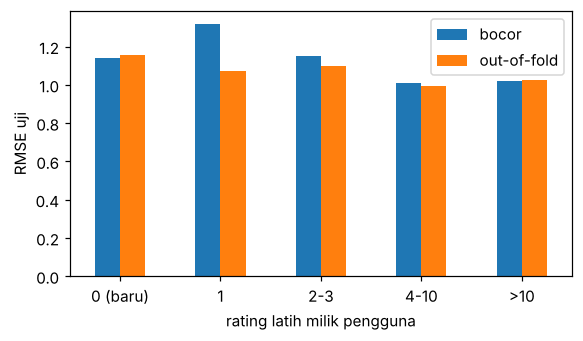

In [4]:
n_tr = test["user"].map(n_per_user).fillna(0).to_numpy()
kelompok = pd.cut(n_tr, [-1, 0, 1, 3, 10, 10**6], labels=["0 (baru)", "1", "2-3", "4-10", ">10"])
rows = []
for kel in kelompok.categories:
    mk = (kelompok == kel)
    if mk.sum() < 20: continue
    rows.append({"rating_latih_pengguna": kel, "n_uji": int(mk.sum()),
                 "bocor": rmse(y[mk], pred_uji["bocor"][mk]),
                 "out-of-fold": rmse(y[mk], pred_uji["out-of-fold"][mk])})
per_kel = pd.DataFrame(rows).set_index("rating_latih_pengguna")
print(per_kel.round(3))

fig, ax = plt.subplots(figsize=(5.4, 3.2))
per_kel[["bocor", "out-of-fold"]].plot.bar(ax=ax, rot=0)
ax.set(xlabel="rating latih milik pengguna", ylabel="RMSE uji")
fig.tight_layout()

**Interpretasi (simulasi).** Kerugian akibat kebocoran terkonsentrasi pada pengguna dengan sedikit rating. Untuk pengguna dengan satu rating latih, fitur bocor adalah fungsi persis dari rating itu sendiri, sehingga model belajar "percaya fitur ini hampir mutlak". Di data uji, fitur itu tidak lagi memuat rating target, dan model yang terlalu percaya menjadi salah. Pada pengguna dengan banyak rating, rata-rata hampir tidak terpengaruh satu baris, jadi selisihnya kecil.

Karena banyak sistem nyata didominasi pengguna berjejak tipis, kebocoran seperti ini dapat tampak sebagai "model bagus di validasi, buruk di produksi".

## 5. Eksperimen C: penghalusan m

Rata-rata dengan sedikit data berisik. Penghalusan menarik rata-rata ke rata-rata global sebesar bobot `m`. Bandingkan beberapa nilai *m* pada pipeline out-of-fold.

In [5]:
rows = []
for mm in (0.1, 1, 5, 20, 100):
    p = evaluasi(m=mm)["out-of-fold"]
    rows.append({"m": mm, "RMSE_uji (out-of-fold)": rmse(y, p)})
print(pd.DataFrame(rows).set_index("m").round(3))

       RMSE_uji (out-of-fold)
m                            
0.1                     1.041
1.0                     1.041
5.0                     1.035
20.0                    1.043
100.0                   1.062


**Interpretasi.** Pengaruh *m* jauh lebih kecil daripada pengaruh kebocoran. Pada simulasi ini, *m* kecil sampai sedang mirip hasilnya. *m* yang sangat besar membuang sinyal per pengguna. Prioritas pertama: pastikan fitur tidak membocorkan target. Penyetelan *m* menyusul.

## Pertanyaan refleksi

1. Mengapa data uji memakai statistik dari *seluruh* data latih, bukan skema lipatan?
2. Apa yang terjadi bila lipatan OOF dibuat per pengguna (bukan per baris)? Kapan itu perlu?
3. Fitur lain apa yang rawan bocor dengan cara serupa (misalnya fitur hasil model lain yang dilatih pada data yang sama)?